# Notebook 5: Benchmark
**IDS 560, Group 4, M5 inventory agent (v4).** Precision, recall and related scores for every part of the system, each compared with simple **baselines**, so the numbers have context. Reads what notebooks 1–4 saved; no language-model calls; about 10–15 minutes.

| Part | What is measured | Compared against |
|---|---|---|
| 1. Retrieval | Precision@5, Recall@10, Hit rate@5, MRR, nDCG@10 | Random passages, keyword only, meaning only (v1–v2), hybrid, hybrid + reranker (ours) |
| 2. "No answer" detection | Precision, recall, F1 | Ours at several relevance cut-offs |
| 3. Agent answers | Accuracy on the forecast questions, citation precision, validation pass rates | — (from notebook 3's saved results) |
| 4. Flags and hold rule | Precision, recall, F1 for items that then sell nothing for 28 days | Ours at three cut-offs; v2's rule (14+ days of zeros) |
| 5. Confidence score | AUC; precision and recall of "Low" for forecasts that miss by more than 100% | A random score |
| 6. Orders | Coverage of actual demand, fill rate, leftover days | Order the forecast only; order last 14 days' sales; ours at 90/95/98% service levels |
| 7. New-item forecast | WAPE, bias | Order zero; category average; ours |

**Relevance labels are automatic** (as agreed): a passage counts as relevant to a test question if it is a passage the agent could use on that date (published by then, right state and category) **and** it matches the test's expected document type and terms. This is an approximation: a passage can mention "snow" without being useful. Hand labels would make parts 1–3 stricter.

Output: `benchmark_summary_v4.csv` (one row per part: our score next to the best baseline) plus a CSV and chart per part, all in `RAG FILES/`.

## Setup

In [1]:
!pip -q install sentence-transformers openai pypdf
import sys, importlib
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass
RAG_FILES = "/content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/RAG FILES/"   # rag_common.py lives here
sys.path.insert(0, RAG_FILES)
import rag_common as rc
importlib.reload(rc)
rc.setup(m5=True, forecasts=True, library=True)
from rag_common import *
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
SUMMARY = []                          # one row per part for benchmark_summary_v4.csv
def summarize(part, metric, ours, baseline_name, baseline, note=""):
    SUMMARY.append({"part": part, "metric": metric, "ours": round(float(ours), 3), "best_baseline": baseline_name,
                    "baseline": round(float(baseline), 3) if baseline is not None else None, "note": note})

def bar(df, cols, title, fname, ylabel=""):
    ax = df[cols].plot.bar(figsize=(1.6 * len(df) + 3, 3.6), rot=0, width=0.8)
    ax.set_title(title); ax.set_ylabel(ylabel); ax.legend(fontsize=8, ncol=len(cols))
    plt.tight_layout(); plt.savefig(out_path(fname), dpi=200, bbox_inches="tight"); plt.show()

Mounted at /content/drive
M5 data: 30,490 series x 1,941 days | prices for 79% of series-weeks
Forecast cube: 15,245 series, 72 weekly forecasts (2014-12-31 to 2016-05-12), 14 days each
Segments: 15,245 series | model error by segment: 2,130 rows
Past launches: 16,610 | new-item method: cascade + own sales


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

... (15 outputs left out)

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/279 [00:00<?, ?B/s]

Library: 7,537 passages from 5,000 documents | reranker on | RELEVANCE_MIN 0.015
Setup done in 89s | files are read from and saved to /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/RAG FILES/ (names end in _v4)


## 1. Retrieval benchmark
For each scored test question (`hit` and `fresh`, 31 questions), every method returns its top 10 passages. With the automatic relevant set R (all passages that match):
- **Precision@5**: share of the top 5 that are relevant.
- **Recall@10**: share of the relevant passages found in the top 10, out of at most 10 (a question with 200 relevant storm reports can't have them all in a top 10, so recall is capped at what fits).
- **Hit rate@5**: at least one relevant passage in the top 5 (what notebook 2's tests check).
- **MRR**: 1 / rank of the first relevant passage (0 if none in the top 10).
- **nDCG@10**: how near the top the relevant passages are (1.0 = all at the top).

33 questions, median 5 relevant passages each (35s)


,precision@5,recall@10,hit@5,MRR,nDCG@10
random,0.073,0.084,0.303,0.141,0.073
keyword only,0.285,0.333,0.576,0.524,0.363
meaning only (v1-v2),0.315,0.391,0.758,0.677,0.424
hybrid + category,0.352,0.386,0.758,0.644,0.421
hybrid + reranker (ours),0.376,0.439,0.848,0.813,0.495


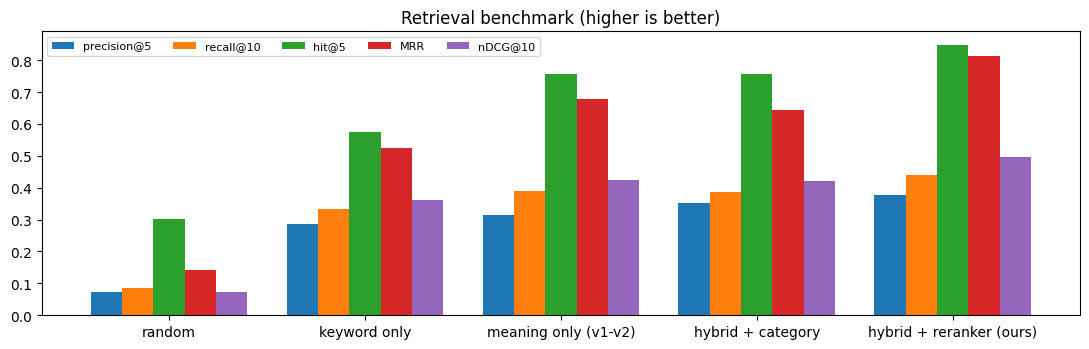

In [2]:
BENCH_METHODS = ["random", "keyword", "dense", "hybrid+category", "full"]
LABELS = {"random": "random", "keyword": "keyword only", "dense": "meaning only (v1-v2)", "hybrid+category": "hybrid + category",
          "full": "hybrid + reranker (ours)"}

def relevant_ids(tid, q, as_of, st, types, terms, kind):
    cand = eligible_passages(as_of, st, category_of(q))
    if kind == "fresh":
        m = (cand["doc_type"] == "beige_book") & ((pd.Timestamp(as_of) - cand["published"]).dt.days <= 60)
    else:
        m = cand["doc_type"].isin(types) if types else pd.Series(True, index=cand.index)
        if terms:
            pat = "|".join(terms)
            m &= cand["text"].str.lower().str.contains(pat) | cand["title"].str.lower().str.contains(pat)
    return set(cand.index[m])

rows = []
t0 = time.time()
for tid, q, as_of, st, types, terms, kind, lookup in TESTS:
    if kind not in ("hit", "fresh"):
        continue
    R = relevant_ids(tid, q, as_of, st, types, terms, kind)
    for meth in BENCH_METHODS:
        res = retrieve(q, as_of, st, k=10, category=category_of(q), method=meth)
        rel = [i in R for i in res.index]
        r10, r5 = rel[:10], rel[:5]
        ideal = min(len(R), 10)
        dcg = sum(1 / np.log2(i + 2) for i, x in enumerate(r10) if x)
        idcg = sum(1 / np.log2(i + 2) for i in range(ideal))
        rows.append({"test": tid, "method": meth, "relevant_in_library": len(R),
                     "precision@5": sum(r5) / 5, "recall@10": (sum(r10) / ideal) if ideal else np.nan, "hit@5": float(any(r5)),
                     "MRR": next((1 / (i + 1) for i, x in enumerate(r10) if x), 0.0), "nDCG@10": (dcg / idcg) if idcg else np.nan})
ret = pd.DataFrame(rows)
ret_table = ret.groupby("method")[["precision@5", "recall@10", "hit@5", "MRR", "nDCG@10"]].mean().reindex(BENCH_METHODS).round(3)
ret_table.index = [LABELS[m] for m in ret_table.index]
print(f"{ret['test'].nunique()} questions, median {int(ret.groupby('test')['relevant_in_library'].first().median())} relevant passages each "
      f"({time.time() - t0:.0f}s)")
display(ret_table)
bar(ret_table, ["precision@5", "recall@10", "hit@5", "MRR", "nDCG@10"], "Retrieval benchmark (higher is better)", "benchmark_retrieval.png")
base = ret_table.drop(index=LABELS["full"])
for metric in ["precision@5", "recall@10", "MRR", "nDCG@10"]:
    summarize("1. Retrieval", metric, ret_table.loc[LABELS["full"], metric], base[metric].idxmax(), base[metric].max())

## 2. "No answer" detection
Treats each question as a yes/no decision: "the library has no answer" (positive) or not. The 10 no-answer questions are the positives; the 31 scored answerable questions the negatives. The agent says "no answer" if every passage is below the relevance cut-off or the top passage is the "what the data does not contain" / "store locations" card.
- **Precision**: when it says "no answer", how often is it right?  **Recall**: how many of the no-answer questions it catches.  **F1**: their balance.

In [3]:
if RERANKER is not None:
    qs = [t for t in TESTS if t[6] in ("hit", "fresh", "no_evidence")]
    tops = []
    for tid, q, as_of, st, types, terms, kind, lookup in qs:
        res = retrieve(q, as_of, st, k=5, category=category_of(q))
        tops.append({"test": tid, "no_answer": kind == "no_evidence", "top_rel": float(res["relevance"].max()) if len(res) else 0.0,
                     "data_card_first": bool(len(res) and res.iloc[0]["series_key"] in NO_DATA_CARDS)})
    tops = pd.DataFrame(tops)
    rows = []
    for cut in sorted({0.005, 0.01, 0.05, 0.1, 0.2, round(rc.RELEVANCE_MIN, 3)}):
        pred = (tops["top_rel"] < cut) | tops["data_card_first"]
        tp, fp, fn = int((pred & tops["no_answer"]).sum()), int((pred & ~tops["no_answer"]).sum()), int((~pred & tops["no_answer"]).sum())
        p = tp / (tp + fp) if tp + fp else 0.0; r = tp / (tp + fn) if tp + fn else 0.0
        rows.append({"cut-off": cut, "ours": cut == round(rc.RELEVANCE_MIN, 3), "precision": p, "recall": r,
                     "F1": 2 * p * r / (p + r) if p + r else 0.0, "said_no_answer": int(pred.sum())})
    noans_table = pd.DataFrame(rows).round(3)
    display(noans_table)
    o = noans_table[noans_table["ours"]].iloc[0]; b = noans_table[~noans_table["ours"]].sort_values("F1").iloc[-1]
    summarize("2. No-answer detection", "F1", o["F1"], f"cut-off {b['cut-off']}", b["F1"], f"precision {o['precision']:.2f}, recall {o['recall']:.2f}")
else:
    noans_table = pd.DataFrame(); print("Reranker not loaded: part 2 skipped")

,cut-off,ours,precision,recall,F1,said_no_answer
0,0.005,False,0.500,0.2,0.286,4
1,0.010,False,0.500,0.2,0.286,4
2,0.015,True,0.500,0.2,0.286,4
3,0.050,False,0.417,0.5,0.455,12
4,0.100,False,0.438,0.7,0.538,16
5,0.200,False,0.444,0.8,0.571,18


## 3. Agent answers (from notebook 3)
Reads notebook 3's saved validation results (no new model calls):
- **Forecast-question accuracy**: share of the forecast-data questions where the answer named the right result.
- **Citation precision**: of the passages an answer cites, the share that are relevant (forecast data for forecast questions; the automatic labels for evidence questions).
- **Validation pass rates** for every check in both matrices.

In [4]:
agent_rows = []
qv, qa, av = (out_path(n) for n in ("question_validation.csv", "question_answers.csv", "agent_validation.csv"))
if os.path.exists(qv):
    qval = pd.read_csv(qv)
    data = qval[qval["kind"] == "data"]
    acc = data["answer_correct"].dropna().astype(bool).mean() if data["answer_correct"].notna().any() else np.nan
    summarize("3. Agent answers", "forecast-question accuracy", acc, None, None, f"{data['answer_correct'].notna().sum()} answered forecast questions")
    agent_rows.append({"measure": "forecast-question accuracy", "value": acc})
    ans = pd.read_csv(qa)
    tests = {t[0]: t for t in TESTS}
    hits = cited_n = 0
    for _, a in ans.dropna(subset=["answer"]).iterrows():
        tid, q, as_of, st, types, terms, kind, lookup = tests[a["test"]]
        if kind == "no_evidence":
            continue
        blocks = {int(n): (dt, body) for n, dt, body in re.findall(r"\[E(\d+)\] \(([a-z_]+),[^\n]*\n(.*?)(?=\n\[E\d+\] \(|\Z)", a["prompt"], flags=re.S)}
        for c in {int(x) for x in re.findall(r"E(\d+)", a["answer"])}:
            if c not in blocks:
                continue
            dt, body = blocks[c]
            ok = dt == "forecast_data" if kind == "data" else ((not types or dt in types) and (not terms or re.search("|".join(terms), body.lower())))
            cited_n += 1; hits += bool(ok)
    cp = hits / cited_n if cited_n else np.nan
    agent_rows.append({"measure": "citation precision", "value": cp})
    summarize("3. Agent answers", "citation precision", cp, None, None, f"{cited_n} citations")
    checks = [c for c in ["lookup_correct", "answer_correct", "states_assumption", "citations_valid", "no_future_sources", "reasons_cited",
                          "no_unsupported_claims", "numbers_verified", "handles_missing"] if c in qval]
    for c in checks:
        agent_rows.append({"measure": f"questions: {c}", "value": qval[c].dropna().astype(bool).mean() if qval[c].notna().any() else np.nan})
if os.path.exists(av):
    aval = pd.read_csv(av)
    for c in ["quantity_correct", "citations_valid", "no_future_sources", "reasons_cited", "names_state_category", "flags_reported",
              "no_unsupported_claims", "numbers_verified", "confidence_stated"]:
        if c in aval and aval[c].notna().any():
            agent_rows.append({"measure": f"orders: {c}", "value": aval[c].dropna().astype(bool).mean()})
agent_table = pd.DataFrame(agent_rows).round(3)
display(agent_table if len(agent_table) else "Notebook 3's results not found: run notebook 3 first")

,measure,value
0,forecast-question accuracy,1.000
1,citation precision,0.722
2,questions: lookup_correct,1.000
3,questions: answer_correct,1.000
4,questions: states_assumption,1.000
5,questions: citations_valid,1.000
6,questions: no_future_sources,1.000
7,questions: reasons_cited,0.800
8,questions: no_unsupported_claims,0.950
9,questions: numbers_verified,1.000


## 4. Flags and the hold rule
On weekly forecast dates every 4 weeks (with 28 days of known sales after them), for every series in the forecasting model's sample that **sold on at least 10 days in the past year and isn't new**:
- **Truly out (the stand-in for "out of stock or discontinued"):** sold nothing in the next 28 days. We can't see shelf stock, so this is the closest observable outcome.
- **Our flag:** a current zero-sales run of 7+ days whose chance, given the item's normal sale rate, is below the cut-off (1 in 100, 1 in 1,000 = ours, 1 in 10,000).
- **v2's rule (baseline):** 14+ days of zeros after selling on 10+ of the 180 days before.

**Precision** = of the flagged items, the share truly out (the manager's false-alarm rate is 1 − precision). **Recall** = of the items truly out, the share flagged beforehand (items that stop suddenly can't be caught, so recall has a ceiling).

18 dates; 14,766 items per date in the population; 8.6% of them sold nothing in the next 28 days


,precision,recall,F1,flagged_per_date
method,,,,
"ours, 1 in 1,000 (current)",0.573,0.588,0.580,1303.389
"ours, 1 in 10,000",0.592,0.529,0.558,1136.333
"ours, 1 in 100",0.537,0.662,0.593,1565.556
v2 rule: 14+ zero days,0.475,0.726,0.575,1940.778


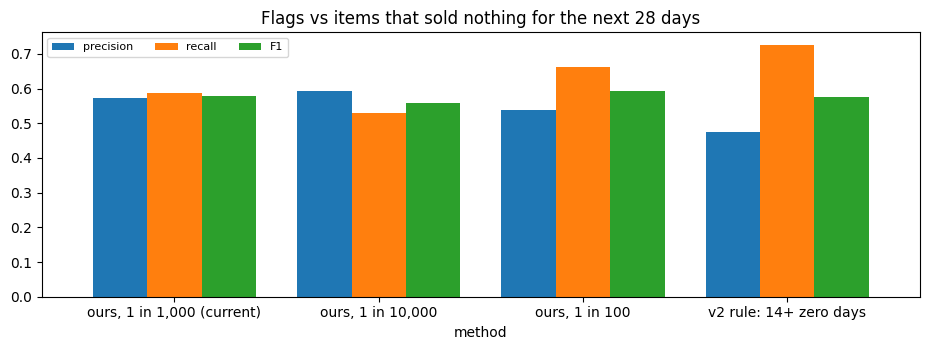

In [5]:
OUT_DAYS = 28
nd = vals.shape[1]
smp = np.array([_r for _r in (rc._ROW.get(split_series_id(s)) for s in (CUBE["ids"] if CUBE else [])) if _r is not None])
pos = vals[smp] > 0
cpos = np.concatenate([np.zeros((len(smp), 1), np.int32), np.cumsum(pos, axis=1, dtype=np.int32)], axis=1)
last_idx = np.maximum.accumulate(np.where(pos, np.arange(nd)[None, :], -1), axis=1)
first_idx = np.where(pos.any(1), pos.argmax(1), nd)
flag_dates = [d for d in (CUBE["origins"][::4] if CUBE else []) if int(day_index[d]) + OUT_DAYS < nd]
rows = []
for d in flag_dates:
    e = int(day_index[d])
    last = last_idx[:, e]
    sold_ever = last >= 0
    zr = np.where(sold_ever, e - last, e + 1)
    start = np.maximum(first_idx, last - 364)
    win = np.maximum(last - start + 1, 1)
    k = np.where(sold_ever, cpos[np.arange(len(smp)), np.maximum(last, 0) + 1] - cpos[np.arange(len(smp)), np.clip(start, 0, nd)], 0)
    p = k / win
    chance = np.where(k > 0, (1 - p) ** zr, 1.0)
    year_days = cpos[:, e + 1] - cpos[:, max(0, e - 364)]
    pop = (year_days >= 10) & ((e - first_idx + 1) >= NEW_ITEM_DAYS)
    out = (cpos[:, e + 1 + OUT_DAYS] - cpos[:, e + 1]) == 0
    k180 = cpos[np.arange(len(smp)), np.maximum(e - zr + 1, 0)] - cpos[np.arange(len(smp)), np.maximum(e - zr - 179, 0)]
    preds = {f"ours, 1 in {int(1 / c):,}" + (" (current)" if c == STOCKOUT_CHANCE else ""): (zr >= STOCKOUT_MIN_DAYS) & (k >= 10) & (chance < c)
             for c in (0.01, 0.001, 0.0001)}
    preds["v2 rule: 14+ zero days"] = (zr >= 14) & (k180 >= 10)
    for name, f in preds.items():
        rows.append({"date": d.date(), "method": name, "flagged": int((f & pop).sum()), "tp": int((f & pop & out).sum()),
                     "out": int((pop & out).sum()), "population": int(pop.sum())})
flag_raw = pd.DataFrame(rows)
if len(flag_raw):
    g = flag_raw.groupby("method")[["flagged", "tp", "out", "population"]].sum()
    g["precision"] = g["tp"] / g["flagged"].where(g["flagged"] > 0); g["recall"] = g["tp"] / g["out"]
    g["F1"] = 2 * g["precision"] * g["recall"] / (g["precision"] + g["recall"])
    g["flagged_per_date"] = g["flagged"] / len(flag_dates)
    flag_table = g[["precision", "recall", "F1", "flagged_per_date"]].round(3)
    print(f"{len(flag_dates)} dates; {int(g['population'].iloc[0] / len(flag_dates)):,} items per date in the population; "
          f"{100 * g['out'].iloc[0] / g['population'].iloc[0]:.1f}% of them sold nothing in the next {OUT_DAYS} days")
    display(flag_table)
    bar(flag_table, ["precision", "recall", "F1"], f"Flags vs items that sold nothing for the next {OUT_DAYS} days", "benchmark_flags.png")
    cur = [i for i in flag_table.index if "(current)" in i][0]
    summarize("4. Flags", "F1", flag_table.loc[cur, "F1"], "v2 rule: 14+ zero days", flag_table.loc["v2 rule: 14+ zero days", "F1"],
              f"precision {flag_table.loc[cur, 'precision']:.2f}, recall {flag_table.loc[cur, 'recall']:.2f}")
    summarize("4. Flags", "precision", flag_table.loc[cur, "precision"], "v2 rule: 14+ zero days", flag_table.loc["v2 rule: 14+ zero days", "precision"])
else:
    flag_table = pd.DataFrame()
del pos, cpos, last_idx

## 5. Confidence score
Same dates and series as notebook 4's confidence check. A forecast is a **big miss** if its 14-day error is more than 100% of what sold (or it forecast sales for an item that sold nothing).
- **AUC**: the chance that a random big miss got a lower confidence score than a random good forecast (0.5 = no better than random, 1.0 = perfect ranking).
- **Precision / recall of "Low"**: of the forecasts rated Low, the share that were big misses; of the big misses, the share rated Low.

In [6]:
CONF_BENCH_SERIES = 4000          # series per date (a random subset keeps this part to a few minutes; None = all)
rng = np.random.default_rng(0)
series = sorted(CUBE["row"]) if CUBE else []
if CONF_BENCH_SERIES and len(series) > CONF_BENCH_SERIES:
    series = list(rng.choice(series, CONF_BENCH_SERIES, replace=False))
rows = []
t0 = time.time()
for d in [pd.Timestamp(x) for x in ["2015-04-01", "2015-08-05", "2015-12-31", "2016-03-31"]]:
    if CUBE is None or d not in CUBE["origins"]:
        continue
    e = int(day_index[d])
    for sid in series:
        item, store = split_series_id(sid)
        if not has_series(item, store):
            continue
        fc_c = lightgbm_forecast(item, store, d)
        seg_c = segment_of(item, store)
        h_c = sales_history(item, store, d)
        conf = forecast_confidence(fc_c, seg_c, item_flags(item, store, d, seg_c), d, h_c)
        n = min(ORDER_DAYS, nd - e - 1)
        a = vals[h_c["row"], e + 1: e + 1 + n].sum(); f = fc_c["mean"][:n].sum()
        score = 10 * {"High": 2, "Medium": 1, "Low": 0}[conf["level"]] + conf["points"]      # level first, then points within a level
        rows.append({"points": score, "level": conf["level"],
                     "big_miss": (abs(f - a) > a) if a > 0 else (f >= 1)})
conf_bench = pd.DataFrame(rows)
if len(conf_bench):
    y = conf_bench["big_miss"].astype(int)
    auc = roc_auc_score(y, -conf_bench["points"]) if y.nunique() == 2 else np.nan
    low = conf_bench["level"] == "Low"
    prec, rec = (y[low].mean(), low[y == 1].mean())
    conf_table_b = pd.DataFrame({"AUC": [auc, 0.5], "Low: precision": [prec, y.mean()], "Low: recall": [rec, low.mean()]},
                                index=["confidence score (ours)", "random score (baseline)"]).round(3)
    print(f"{len(conf_bench):,} forecasts ({time.time() - t0:.0f}s); {100 * y.mean():.0f}% were big misses")
    display(conf_table_b)
    summarize("5. Confidence", "AUC", auc, "random score", 0.5, f"Low: precision {prec:.2f}, recall {rec:.2f}")
else:
    conf_table_b = pd.DataFrame()

16,000 forecasts (16s); 20% were big misses


,AUC,Low: precision,Low: recall
confidence score (ours),0.585,0.239,0.897
random score (baseline),0.500,0.197,0.741


## 6. Orders
On notebook 4's backtest dates, for a random subset of series (orders that are not held): would the order have covered the next 14 days' actual sales? Stock on hand is 0, so the order equals the order-up-to level.
- **Ours** at 90%, 95% (current) and 98% service levels: forecast + safety stock from the item's own past errors.
- **Forecast only:** order exactly the 14-day forecast (no safety stock).
- **Naive:** order what sold in the last 14 days.

**Coverage** = share of orders at least as large as actual sales; **fill rate** = share of units sold that the order covered; **leftover days** = units left over, in days of average demand (the cost of the buffer).

14,360 orders (50s)


,coverage,fill rate,leftover days
naive: last 14 days,0.563,0.835,2.386
forecast only,0.656,0.867,2.244
ours 90%,0.948,0.977,8.420
ours 95% (current),0.973,0.988,10.945
ours 98%,0.986,0.994,13.672


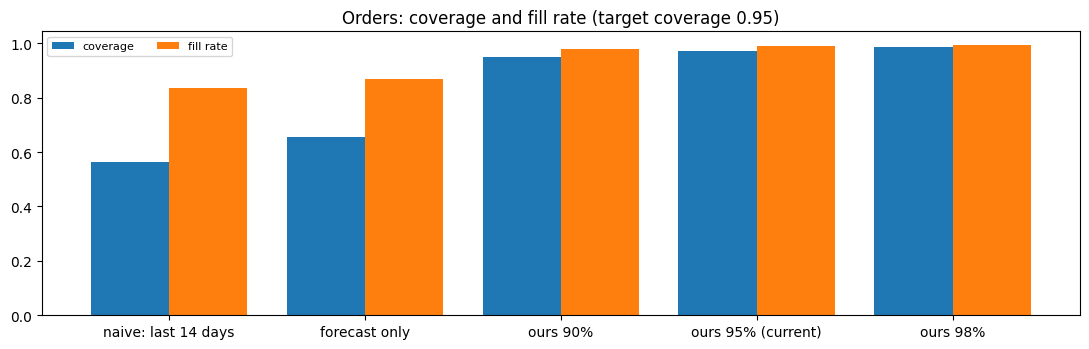

In [7]:
ORDER_BENCH_SERIES = 2000
full = [d for d in (CUBE["origins"] if CUBE else []) if int(day_index[d]) + ORDER_DAYS < nd]
bdates = [full[i] for i in np.linspace(0, len(full) - 1, 8).round().astype(int)] if full else []
ser = list(rng.choice(sorted(CUBE["row"]), min(ORDER_BENCH_SERIES, len(CUBE["row"])), replace=False)) if CUBE else []
rows = []
t0 = time.time()
for d in bdates:
    e = int(day_index[d])
    for sid in ser:
        item, store = split_series_id(sid)
        if not has_series(item, store):
            continue
        po = place_order(item, store, d, on_hand=0)
        if po["order"]["hold"]:
            continue
        row = po["history"]["row"]
        actual = float(vals[row, e + 1: e + 1 + ORDER_DAYS].sum())
        r = {"actual": actual, "forecast only": math.ceil(float(np.sum(po["forecast"]["mean"][:ORDER_DAYS]))),
             "naive: last 14 days": float(vals[row, e - 13: e + 1].sum()), "ours 95% (current)": po["order"]["order_qty"]}
        for sl in (0.90, 0.98):
            safety = item_safety_stock(item, store, d, ORDER_DAYS, sl)
            r[f"ours {int(sl * 100)}%"] = order_quantity(po["forecast"]["mean"], po["forecast"]["sd"], 0, service_level=sl, safety=safety)["order_qty"]
        rows.append(r)
ob = pd.DataFrame(rows)
if len(ob):
    cols = ["naive: last 14 days", "forecast only", "ours 90%", "ours 95% (current)", "ours 98%"]
    order_table = pd.DataFrame({c: {"coverage": (ob[c] >= ob["actual"]).mean(),
                                    "fill rate": 1 - (ob["actual"] - ob[c]).clip(lower=0).sum() / ob["actual"].sum(),
                                    "leftover days": (ob[c] - ob["actual"]).clip(lower=0).sum() / (ob["actual"].sum() / ORDER_DAYS)} for c in cols}).T.round(3)
    print(f"{len(ob):,} orders ({time.time() - t0:.0f}s)")
    display(order_table)
    bar(order_table, ["coverage", "fill rate"], "Orders: coverage and fill rate (target coverage 0.95)", "benchmark_orders.png")
    best_b = order_table.loc[["naive: last 14 days", "forecast only"], "coverage"].idxmax()
    summarize("6. Orders", "coverage", order_table.loc["ours 95% (current)", "coverage"], best_b, order_table.loc[best_b, "coverage"],
              f"leftover days {order_table.loc['ours 95% (current)', 'leftover days']:.1f}")
else:
    order_table = pd.DataFrame()

## 7. New-item forecast
Past launches treated as new (2015 launches, the confirmation set of notebook 4), forecasting their 14-day sales at launch, after 2 weeks and after 4 weeks:
- **Ours:** the method chosen in notebook 4 (`NEW_ITEM_STRATEGY`).
- **Order zero:** predict nothing (WAPE is 100% by definition).
- **Category average:** the average 14-day sales of every item in the same category and state over the last 4 weeks.

In [8]:
lo, hi = int(day_index[pd.Timestamp("2015-01-01")]), int(day_index[pd.Timestamp("2015-10-31")])
pool = np.flatnonzero((L_FIRST >= lo) & (L_FIRST <= hi) & (L_FIRST + 28 + 14 <= nd))
pick = rng.choice(pool, size=min(1000, len(pool)), replace=False) if len(pool) else []
state_cat = (ids["state_id"] + "|" + ids["cat_id"]).to_numpy()
rows = []
for li in pick:
    r, f = L_ROWS[li], L_FIRST[li]
    for age in (0, 14, 28):
        d_idx = f + age - 1
        actual = float(vals[r, f + age: f + age + 14].sum())
        est = new_item_estimate(r, d_idx, NEW_ITEM_STRATEGY, NEW_ITEM_BLEND)
        peers = np.flatnonzero(state_cat == state_cat[r])
        cat_avg = float(vals[peers, d_idx - 27: d_idx + 1].mean()) * 14
        rows.append({"age": age, "actual": actual, "ours": est["total"] if est else np.nan, "order zero": 0.0, "category average": cat_avg})
ni = pd.DataFrame(rows).dropna()
if len(ni):
    ni_table = pd.DataFrame({c: {"WAPE": (ni[c] - ni["actual"]).abs().sum() / ni["actual"].sum(),
                                 "bias": (ni[c] - ni["actual"]).sum() / ni["actual"].sum()} for c in ["order zero", "category average", "ours"]}).T.round(3)
    print(f"{len(ni):,} new-item forecasts; ours = {NEW_ITEM_STRATEGY}" + (" + own sales" if NEW_ITEM_BLEND else ""))
    display(ni_table)
    best_b = ni_table.loc[["order zero", "category average"], "WAPE"].idxmin()
    summarize("7. New-item forecast", "WAPE (lower is better)", ni_table.loc["ours", "WAPE"], best_b, ni_table.loc[best_b, "WAPE"],
              f"bias {ni_table.loc['ours', 'bias']:+.2f}")
else:
    ni_table = pd.DataFrame()

2,724 new-item forecasts; ours = cascade + own sales


,WAPE,bias
order zero,1.000,-1.000
category average,1.193,0.683
ours,0.613,-0.218


## Summary and save
One row per part: our score next to the best baseline (for WAPE, lower is better; for everything else, higher is better).

In [9]:
summary = pd.DataFrame(SUMMARY)
display(summary)
summary.to_csv(out_path("benchmark_summary.csv"), index=False)
for name, df in [("benchmark_retrieval.csv", ret_table), ("benchmark_no_answer.csv", noans_table), ("benchmark_agent.csv", agent_table),
                 ("benchmark_flags.csv", flag_table), ("benchmark_confidence.csv", conf_table_b), ("benchmark_orders.csv", order_table),
                 ("benchmark_new_items.csv", ni_table)]:
    if len(df):
        df.to_csv(out_path(name))
print("Saved benchmark_summary_v4.csv, one CSV per part and the charts to", RAG_DIR)

,part,metric,ours,best_baseline,baseline,note
0,1. Retrieval,precision@5,0.376,hybrid + category,0.352,
1,1. Retrieval,recall@10,0.439,meaning only (v1-v2),0.391,
2,1. Retrieval,MRR,0.813,meaning only (v1-v2),0.677,
3,1. Retrieval,nDCG@10,0.495,meaning only (v1-v2),0.424,
4,2. No-answer detection,F1,0.286,cut-off 0.2,0.571,"precision 0.50, recall 0.20"
5,3. Agent answers,forecast-question accuracy,1.000,None,NaN,12 answered forecast questions
6,3. Agent answers,citation precision,0.722,None,NaN,18 citations
7,4. Flags,F1,0.580,v2 rule: 14+ zero days,0.575,"precision 0.57, recall 0.59"
8,4. Flags,precision,0.573,v2 rule: 14+ zero days,0.475,
9,5. Confidence,AUC,0.585,random score,0.500,"Low: precision 0.24, recall 0.90"


Saved benchmark_summary_v4.csv, one CSV per part and the charts to /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/RAG FILES/
